In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from matplotlib.path import Path
from matplotlib.transforms import Affine2D
from ipywidgets import interact, interactive
import ipywidgets as widgets


#Player Totals Dataset
PD= pd.read_csv("Player Totals.csv").drop(columns=['g','gs','ft','fta','ft_percent','lg'])
PD=PD.query("season >= 1980")
PD.info()

#Team Totals Dataset
TD= pd.read_csv("Team Totals.csv").drop(columns=['lg'])
TD=TD.query("season >= 1980")
#TD.info()

TS=pd.read_csv("Team Summaries.csv")

<class 'pandas.DataFrame'>
RangeIndex: 25790 entries, 0 to 25789
Data columns (total 27 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   season        25790 non-null  int64  
 1   player        25790 non-null  str    
 2   player_id     25790 non-null  str    
 3   age           25790 non-null  float64
 4   team          25790 non-null  str    
 5   pos           25789 non-null  str    
 6   mp            25790 non-null  float64
 7   fg            25790 non-null  int64  
 8   fga           25790 non-null  int64  
 9   fg_percent    25642 non-null  float64
 10  x3p           25790 non-null  float64
 11  x3pa          25790 non-null  float64
 12  x3p_percent   21794 non-null  float64
 13  x2p           25790 non-null  float64
 14  x2pa          25790 non-null  float64
 15  x2p_percent   25537 non-null  float64
 16  e_fg_percent  25642 non-null  float64
 17  orb           25790 non-null  float64
 18  drb           25790 non-null  float64

In [2]:
def big_number(ax, value, label, color):
    """Show a large number above a short label in an empty axes."""
    ax.set_axis_off()
    ax.text(0, 0.55, value, fontsize=40, fontweight='bold', color=color,
            transform=ax.transAxes, va='bottom')
    ax.text(0, 0.45, label, fontsize=11, color='dimgray',
            transform=ax.transAxes, va='top')

## Dashboard visuals

Each section answers one sub-question from the project doc. Seasons are named by the year they end (2024 = the 2023–24 season). We keep 1980–2024.

In [3]:
# Settings and shared tables for the dashboard charts
FIRST, LAST = 1980, 2024
sns.set_theme(style='whitegrid', context='notebook')
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, RED = '#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#e34948'
POS_ORDER = ['PG', 'SG', 'SF', 'PF', 'C']
POS_COLORS = dict(zip(POS_ORDER, [BLUE, ORANGE, AQUA, YELLOW, MAGENTA]))

def true_shooting(pts, fga, fta):
    """TS% = PTS / (2 * (FGA + 0.44 * FTA)), as a percent."""
    return 100 * pts / (2 * (fga + 0.44 * fta))

def decade(season):
    return f"{(season // 10) * 10}s"

# Teams: one row per team per season, with per-game and derived stats
TEAMS = TD.query("@FIRST <= season <= @LAST").copy()
for col in ['pts', 'fga', 'x3pa', 'fta']:
    TEAMS[f'{col}_pg'] = TEAMS[col] / TEAMS['g']
TEAMS['three_share'] = 100 * TEAMS['x3pa'] / TEAMS['fga']
TEAMS['ts'] = true_shooting(TEAMS['pts'], TEAMS['fga'], TEAMS['fta'])

# Basketball-Reference adds a "League Average" row for each season
LEAGUE = TEAMS[TEAMS['team'] == 'League Average'].set_index('season').sort_index()
TEAMS = TEAMS[TEAMS['team'] != 'League Average']

# Champions are not in the dataset, so we list them here
CHAMPIONS = {
    1980: 'LAL', 1981: 'BOS', 1982: 'LAL', 1983: 'PHI', 1984: 'BOS', 1985: 'LAL', 1986: 'BOS',
    1987: 'LAL', 1988: 'LAL', 1989: 'DET', 1990: 'DET', 1991: 'CHI', 1992: 'CHI', 1993: 'CHI',
    1994: 'HOU', 1995: 'HOU', 1996: 'CHI', 1997: 'CHI', 1998: 'CHI', 1999: 'SAS', 2000: 'LAL',
    2001: 'LAL', 2002: 'LAL', 2003: 'SAS', 2004: 'DET', 2005: 'SAS', 2006: 'MIA', 2007: 'SAS',
    2008: 'BOS', 2009: 'LAL', 2010: 'LAL', 2011: 'DAL', 2012: 'MIA', 2013: 'MIA', 2014: 'SAS',
    2015: 'GSW', 2016: 'CLE', 2017: 'GSW', 2018: 'GSW', 2019: 'TOR', 2020: 'LAL', 2021: 'MIL',
    2022: 'GSW', 2023: 'DEN', 2024: 'BOS'}

# Players: keep one row per player per season.
# A traded player has a combined row (team = '2TM', '3TM' or 'TOT') plus one row per team.
PLAYERS = PD.query("@FIRST <= season <= @LAST").dropna(subset=['pos']).copy()
PLAYERS['combined'] = PLAYERS['team'].str.fullmatch(r'\d+TM|TOT')
traded = PLAYERS.loc[PLAYERS['combined'], ['season', 'player_id']].drop_duplicates()
PLAYERS = PLAYERS.merge(traded.assign(was_traded=True), on=['season', 'player_id'], how='left')
PLAYERS = PLAYERS[PLAYERS['combined'] | PLAYERS['was_traded'].isna()]
PLAYERS['pos'] = PLAYERS['pos'].str.split('-').str[0]

STATS_36 = {'x3pa': '3PA', 'trb': 'Rebounds', 'ast': 'Assists'}
for col in STATS_36:
    PLAYERS[f'{col}_36'] = 36 * PLAYERS[col] / PLAYERS['mp']

# Position averages per season, weighted by minutes played
POS_SEASON = PLAYERS.groupby(['season', 'pos'])[['mp', *STATS_36]].sum()
for col in STATS_36:
    POS_SEASON[f'{col}_36'] = 36 * POS_SEASON[col] / POS_SEASON['mp']
POS_SEASON = POS_SEASON.reset_index()

print(f"{len(LEAGUE)} league seasons, {len(TEAMS)} team seasons, {len(PLAYERS)} player seasons")

45 league seasons, 1254 team seasons, 19399 player seasons


### Summary: change between two seasons
Move the sliders to compare any two seasons.

In [4]:
def compare_seasons(start=FIRST, end=LAST):
    """Show how four league averages changed between two seasons."""
    if start >= end:
        print('Pick a start season that is before the end season.')
        return
    a, b = LEAGUE.loc[start], LEAGUE.loc[end]
    tiles = [('three_share', 'shots from three', '%'),
             ('ts', 'true shooting', '%'),
             ('pts_pg', 'points per game', ''),
             ('fga_pg', 'FGA per game', '')]
    fig, axes = plt.subplots(1, 4, figsize=(14, 2.2))
    for ax, (col, label, unit) in zip(axes, tiles):
        change = b[col] - a[col]
        big_number(ax, f"{b[col]:.1f}{unit}",
                   f"{label} in {end}\n{change:+.1f} since {start} ({a[col]:.1f}{unit})",
                   BLUE if change >= 0 else ORANGE)
    plt.show()

interact(compare_seasons,
         start=widgets.IntSlider(value=FIRST, min=FIRST, max=LAST - 1, description='Start'),
         end=widgets.IntSlider(value=LAST, min=FIRST + 1, max=LAST, description='End'));

interactive(children=(IntSlider(value=1980, description='Start', max=2023, min=1980), IntSlider(value=2024, de…

### Q1: How has the way teams generate points changed?
**S1.1** Compute 3PA ÷ FGA for each season, then correlate it with season.
**S1.2** Correlate true shooting % with points per game across seasons.

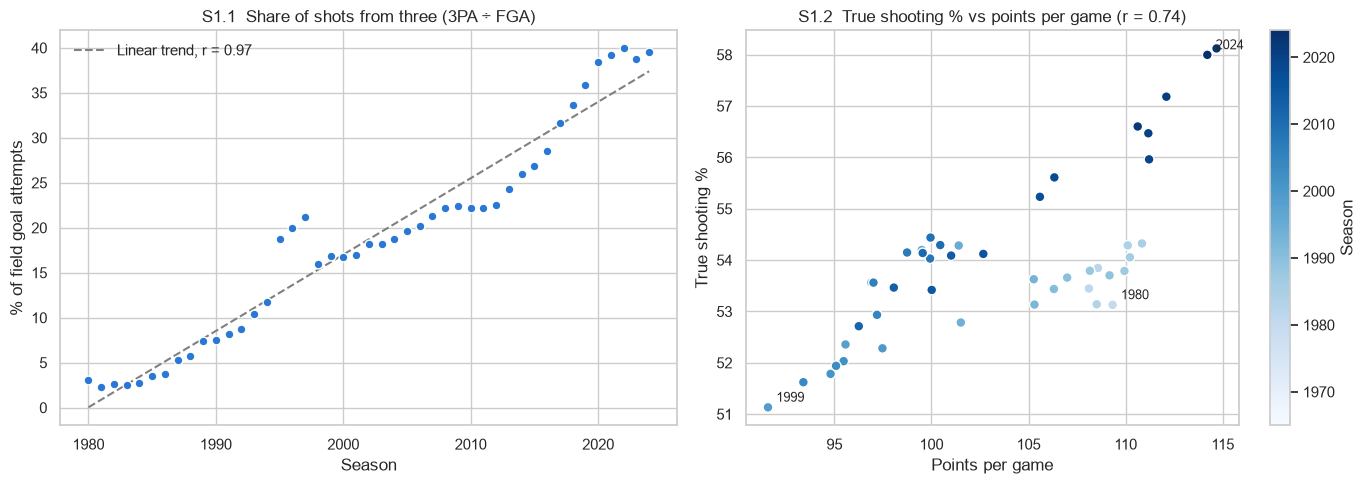

3PA share: 3.1% in 1980, 39.5% in 2024, about +8.5 points per decade.
TS% vs PPG: r = 0.74, p = 7.61e-09


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# S1.1: three-point share by season, with a linear trend
fit = stats.linregress(LEAGUE.index, LEAGUE['three_share'])
ax1.scatter(LEAGUE.index, LEAGUE['three_share'], color=BLUE, s=40, edgecolor='white', zorder=3)
ax1.plot(LEAGUE.index, fit.intercept + fit.slope * LEAGUE.index, '--', color='gray',
         label=f'Linear trend, r = {fit.rvalue:.2f}')
ax1.set(title='S1.1  Share of shots from three (3PA ÷ FGA)', xlabel='Season', ylabel='% of field goal attempts')
ax1.legend(frameon=False)

# S1.2: efficiency vs volume, one dot per season, darker = more recent
r, p = stats.pearsonr(LEAGUE['pts_pg'], LEAGUE['ts'])
dots = ax2.scatter(LEAGUE['pts_pg'], LEAGUE['ts'], c=LEAGUE.index, cmap='Blues', vmin=FIRST - 15,
                   s=50, edgecolor='white')
fig.colorbar(dots, ax=ax2, label='Season')
for season in [FIRST, 1999, LAST]:
    ax2.annotate(str(season), (LEAGUE.loc[season, 'pts_pg'], LEAGUE.loc[season, 'ts']),
                 xytext=(6, 4), textcoords='offset points', fontsize=9)
ax2.set(title=f'S1.2  True shooting % vs points per game (r = {r:.2f})',
        xlabel='Points per game', ylabel='True shooting %')

plt.tight_layout()
plt.show()
print(f"3PA share: {LEAGUE['three_share'].iloc[0]:.1f}% in {FIRST}, {LEAGUE['three_share'].iloc[-1]:.1f}% in {LAST}, "
      f"about +{fit.slope * 10:.1f} points per decade.")
print(f"TS% vs PPG: r = {r:.2f}, p = {p:.3g}")

### Q2: How have the roles of each position changed?
**S2.1** Three-point attempts per 36 minutes, by position (weighted by minutes played).
**S2.2** Have the positions become more alike? The left chart measures how far apart the five position averages are (coefficient of variation = std ÷ mean; lower = more alike). The box plots show players with at least 500 minutes.

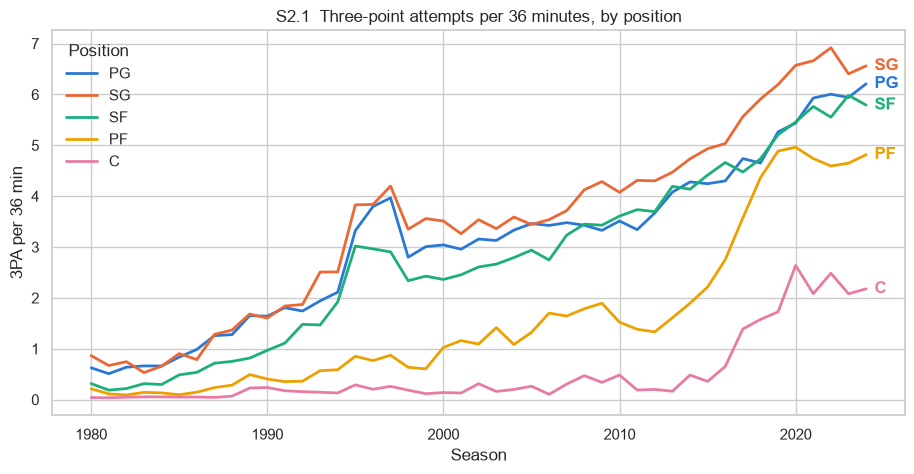

season,1980,2000,2024
pos,,,
PG,0.63,3.04,6.21
SG,0.86,3.51,6.56
SF,0.32,2.36,5.79
PF,0.21,1.03,4.82
C,0.04,0.14,2.18


In [6]:
# S2.1: 3PA per 36 minutes by position
fig, ax = plt.subplots(figsize=(11, 5))
for pos in POS_ORDER:
    d = POS_SEASON[POS_SEASON['pos'] == pos]
    ax.plot(d['season'], d['x3pa_36'], color=POS_COLORS[pos], lw=2, label=pos)
    ax.annotate(pos, (d['season'].iloc[-1], d['x3pa_36'].iloc[-1]), xytext=(6, 0),
                textcoords='offset points', va='center', color=POS_COLORS[pos], fontweight='bold')
ax.set(title='S2.1  Three-point attempts per 36 minutes, by position', xlabel='Season', ylabel='3PA per 36 min')
ax.legend(title='Position', frameon=False)
plt.show()

POS_SEASON.query("season in [@FIRST, 2000, @LAST]").pivot(index='pos', columns='season', values='x3pa_36').loc[POS_ORDER].round(2)

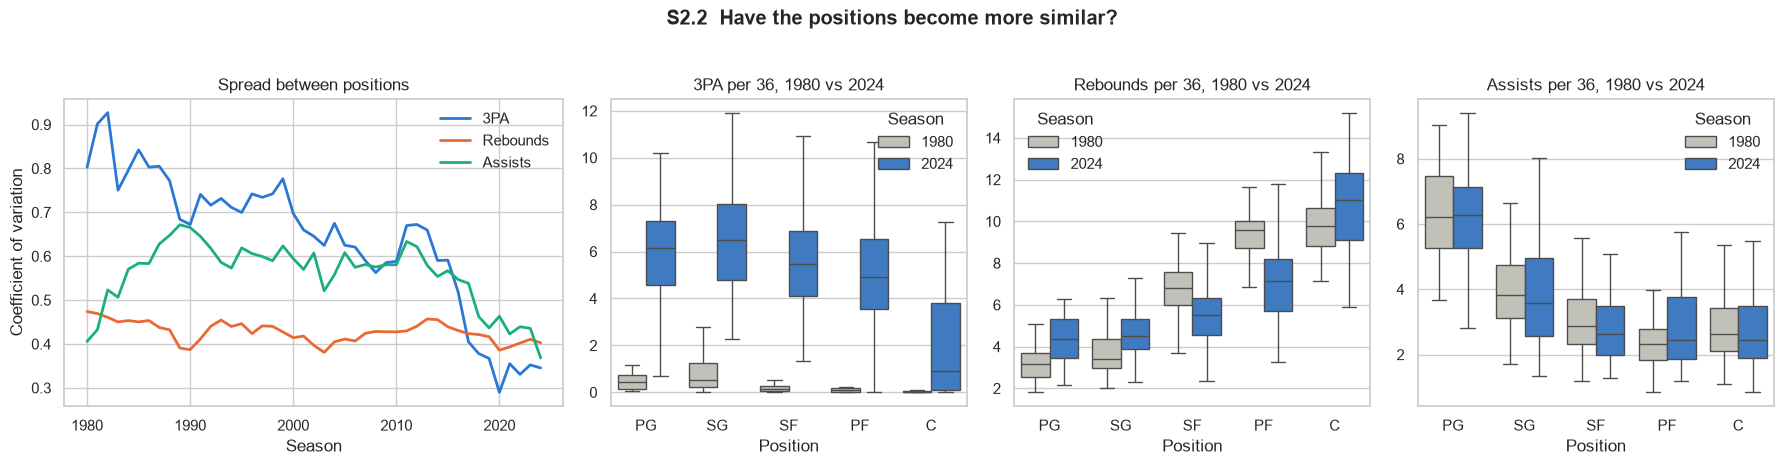

,3PA,Rebounds,Assists
season,,,
1980,0.80,0.47,0.41
2000,0.70,0.41,0.59
2024,0.35,0.40,0.37


In [7]:
# S2.2: are the positions more alike?
spread = (POS_SEASON.groupby('season')[[f'{c}_36' for c in STATS_36]]
          .agg(lambda s: s.std() / s.mean())
          .rename(columns={f'{c}_36': name for c, name in STATS_36.items()}))

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), gridspec_kw={'width_ratios': [1.4, 1, 1, 1]})
for name, color in zip(spread.columns, [BLUE, ORANGE, AQUA]):
    axes[0].plot(spread.index, spread[name], color=color, lw=2, label=name)
axes[0].set(title='Spread between positions', xlabel='Season', ylabel='Coefficient of variation')
axes[0].legend(frameon=False)

regulars = PLAYERS.query("mp >= 500 and season in [@FIRST, @LAST]")
for ax, (col, name) in zip(axes[1:], STATS_36.items()):
    sns.boxplot(data=regulars, x='pos', y=f'{col}_36', hue='season', order=POS_ORDER,
                palette=['#c3c2b7', BLUE], showfliers=False, ax=ax)
    ax.set(title=f'{name} per 36, {FIRST} vs {LAST}', xlabel='Position', ylabel='')
    ax.legend(title='Season', frameon=False)
plt.suptitle('S2.2  Have the positions become more similar?', y=1.03, fontweight='bold')
plt.tight_layout()
plt.show()

spread.loc[[FIRST, 2000, LAST]].round(2)

### Q3: How has the link between playing style and winning changed?
**S3.1** Correlate team traits with win % in each decade. This needs `Team Summaries.csv` from the Kaggle dataset, because Team Totals has no wins or losses.
**S3.2** How far each champion was from the league average.

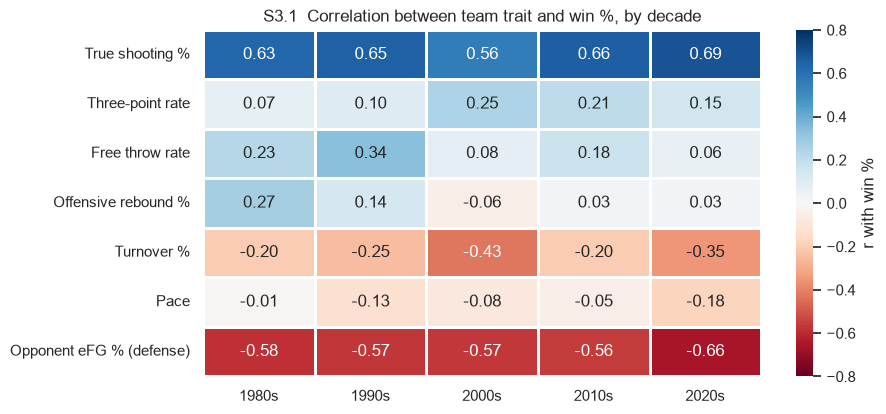

Strongest positive trait per decade:
1980s    True shooting %
1990s    True shooting %
2000s    True shooting %
2010s    True shooting %
2020s    True shooting %


In [8]:
# S3.1: correlation between team traits and win % by decade
from pathlib import Path

if Path('Team Summaries.csv').exists():
    SUM = pd.read_csv('Team Summaries.csv').query(
        "lg == 'NBA' and @FIRST <= season <= @LAST and team != 'League Average'").copy()
    TRAITS = {'ts_percent': 'True shooting %', 'x3p_ar': 'Three-point rate', 'f_tr': 'Free throw rate',
              'orb_percent': 'Offensive rebound %', 'tov_percent': 'Turnover %', 'pace': 'Pace',
              'opp_e_fg_percent': 'Opponent eFG % (defense)'}
    for col in ['w', 'l', *TRAITS]:
        SUM[col] = pd.to_numeric(SUM[col], errors='coerce')
    SUM['win_pct'] = SUM['w'] / (SUM['w'] + SUM['l'])
    SUM['decade'] = SUM['season'].map(decade)

    corr = pd.DataFrame({dec: g[list(TRAITS)].corrwith(g['win_pct'])
                         for dec, g in SUM.groupby('decade')}).rename(index=TRAITS)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu', center=0, vmin=-0.8, vmax=0.8,
                linewidths=2, cbar_kws={'label': 'r with win %'}, ax=ax)
    ax.set(title='S3.1  Correlation between team trait and win %, by decade', xlabel='', ylabel='')
    plt.show()
    print('Strongest positive trait per decade:')
    print(corr.idxmax().to_string())
else:
    print('S3.1 needs Team Summaries.csv (it has wins and losses). '
          'Download it from the Kaggle dataset and put it in the same folder as the other CSVs.')

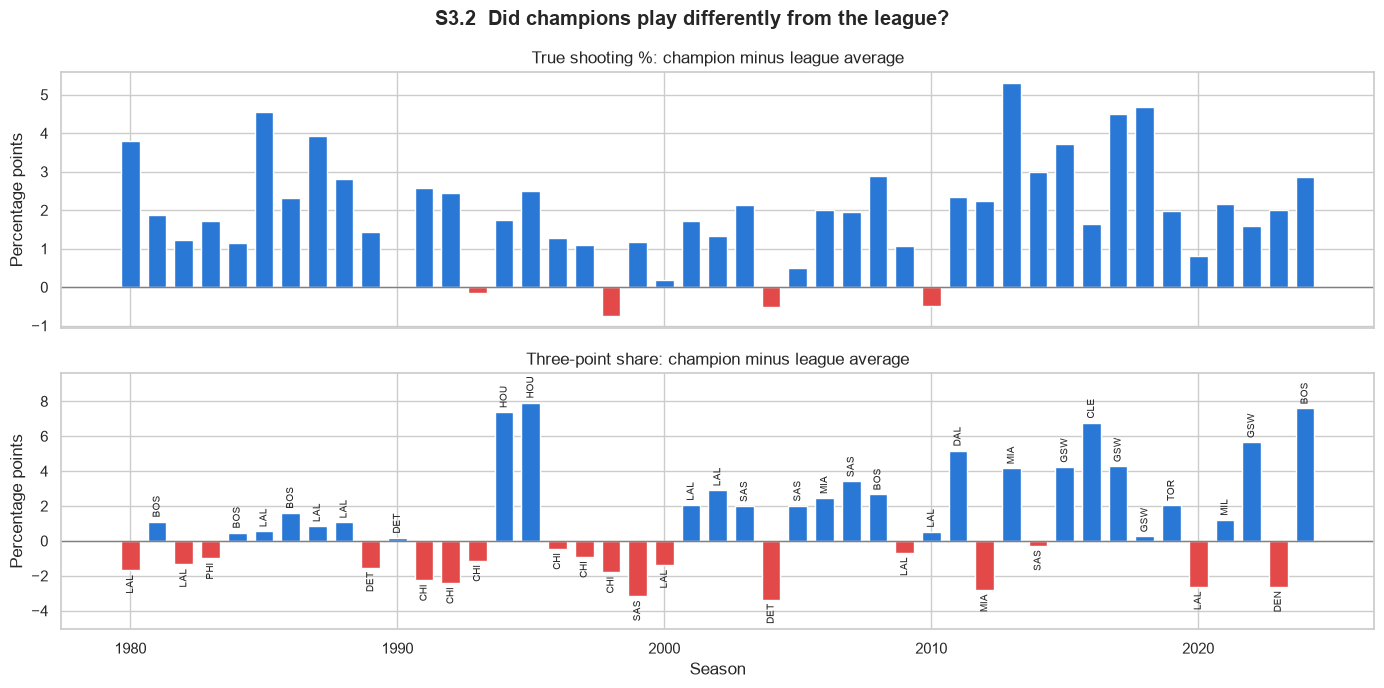

ts_gap          three_gap         
         mean mean_abs      mean mean_abs
decade                                   
1980s    2.48     2.48      0.00     1.12
1990s    1.20     1.38      0.34     2.76
2000s    1.33     1.43      1.21     2.29
2010s    2.89     2.99      2.44     3.05
2020s    1.89     1.89      1.83     3.95

In [9]:
# S3.2: champion minus league average, each season
champs = (pd.DataFrame(CHAMPIONS.items(), columns=['season', 'abbreviation'])
          .merge(TEAMS, on=['season', 'abbreviation'], how='left'))
assert champs['team'].notna().all(), 'A champion abbreviation did not match Team Totals'
champs['ts_gap'] = champs['ts'] - champs['season'].map(LEAGUE['ts'])
champs['three_gap'] = champs['three_share'] - champs['season'].map(LEAGUE['three_share'])

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, (col, label) in zip(axes, [('ts_gap', 'True shooting %'), ('three_gap', 'Three-point share')]):
    ax.bar(champs['season'], champs[col], color=np.where(champs[col] >= 0, BLUE, RED), width=0.7)
    ax.axhline(0, color='gray', lw=1)
    ax.set(ylabel='Percentage points', title=f'{label}: champion minus league average')
for _, row in champs.iterrows():
    above = row['three_gap'] >= 0
    axes[1].annotate(row['abbreviation'], (row['season'], row['three_gap']), xytext=(0, 3 if above else -3),
                     textcoords='offset points', ha='center', va='bottom' if above else 'top',
                     fontsize=7, rotation=90)
axes[1].margins(y=0.15)
axes[1].set_xlabel('Season')
plt.suptitle('S3.2  Did champions play differently from the league?', fontweight='bold')
plt.tight_layout()
plt.show()

# Average gap by decade: mean shows the direction, mean_abs shows the size
champs['decade'] = champs['season'].map(decade)
champs.groupby('decade')[['ts_gap', 'three_gap']].agg(['mean', lambda s: s.abs().mean()]).rename(
    columns={'<lambda_0>': 'mean_abs'}).round(2)

### Q4: How has scoring efficiency changed compared to scoring volume?
**S4.1** Trends in points, field goal attempts and three-point attempts per game. Each is on its own scale.
**S4.2** True shooting % = PTS ÷ (2 × (FGA + 0.44 × FTA)) for each season, correlated with season.

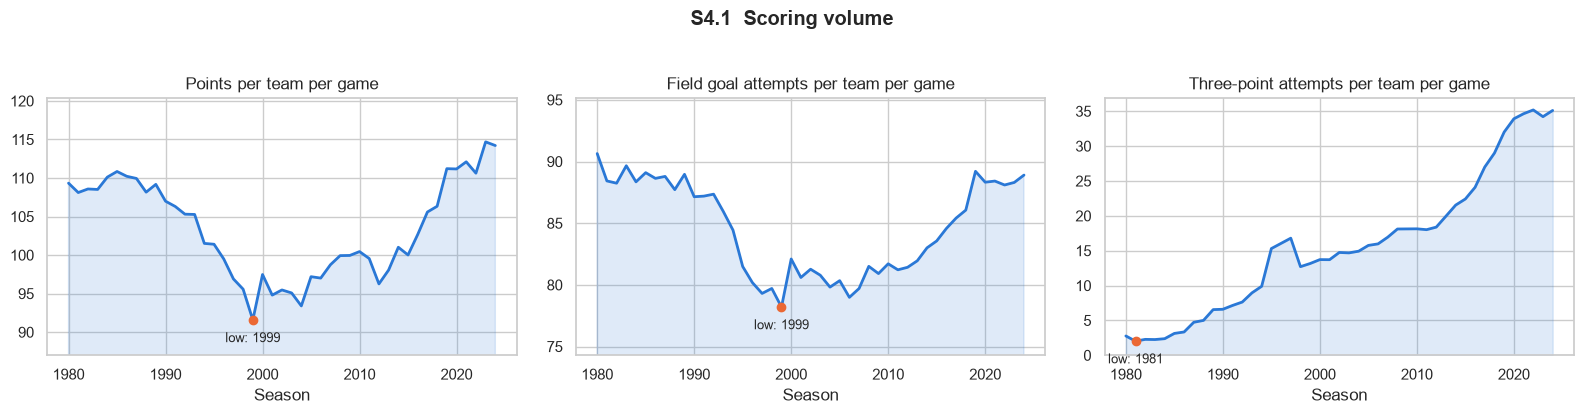

In [10]:
# S4.1: scoring volume, one chart per measure
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, (col, label) in zip(axes, [('pts_pg', 'Points'), ('fga_pg', 'Field goal attempts'),
                                   ('x3pa_pg', 'Three-point attempts')]):
    ax.fill_between(LEAGUE.index, LEAGUE[col], alpha=0.15, color=BLUE)
    ax.plot(LEAGUE.index, LEAGUE[col], color=BLUE, lw=2)
    low = LEAGUE[col].idxmin()
    ax.scatter([low], [LEAGUE.loc[low, col]], color=ORANGE, zorder=3)
    ax.annotate(f'low: {low}', (low, LEAGUE.loc[low, col]), xytext=(0, -16), textcoords='offset points',
                ha='center', fontsize=9)
    ax.set(title=f'{label} per team per game', xlabel='Season')
    ax.set_ylim(0 if col == 'x3pa_pg' else LEAGUE[col].min() * 0.95, LEAGUE[col].max() * 1.05)
plt.suptitle('S4.1  Scoring volume', fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

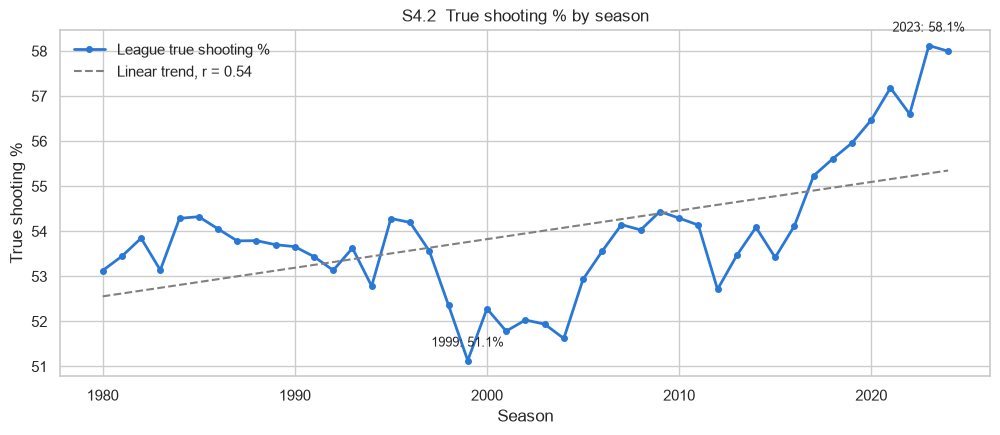

,PPG % change,FGA % change,TS% % change
season,,,
1980,0.0,0.0,0.0
1999,-16.2,-13.7,-3.8
2010,-8.1,-9.9,2.2
2024,4.5,-1.9,9.2


In [11]:
# S4.2: scoring efficiency by season
fit = stats.linregress(LEAGUE.index, LEAGUE['ts'])
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(LEAGUE.index, LEAGUE['ts'], color=BLUE, lw=2, marker='o', ms=4, label='League true shooting %')
ax.plot(LEAGUE.index, fit.intercept + fit.slope * LEAGUE.index, '--', color='gray',
        label=f'Linear trend, r = {fit.rvalue:.2f}')
for season in [LEAGUE['ts'].idxmin(), LEAGUE['ts'].idxmax()]:
    ax.annotate(f"{season}: {LEAGUE.loc[season, 'ts']:.1f}%", (season, LEAGUE.loc[season, 'ts']),
                xytext=(0, 10), textcoords='offset points', ha='center', fontsize=9)
ax.set(title='S4.2  True shooting % by season', xlabel='Season', ylabel='True shooting %')
ax.legend(frameon=False)
plt.show()

# Volume and efficiency side by side, as change since the first season
change = LEAGUE[['pts_pg', 'fga_pg', 'ts']].apply(lambda s: 100 * (s / s.iloc[0] - 1))
change.loc[[FIRST, 1999, 2010, LAST]].round(1).rename(columns={'pts_pg': 'PPG % change', 'fga_pg': 'FGA % change', 'ts': 'TS% % change'})